# Visualizing Earnings with Seaborn

In this activity, you will use Seaborn to explore patterns in `earnings.csv`. The exercises begin with specific plot and code hints. Later, you will decide which visualization best answers each question.

For every plot:

- Include a clear title and axis labels.
- Choose figure dimensions that make labels readable.
- Write 1-3 sentences explaining what the visualization shows.
- Describe associations carefully; a plot alone does not establish causation.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")

earnings = pd.read_csv("earnings.csv")
earnings.head()

Matplotlib is building the font cache; this may take a moment.


,wages,age,gender,race,marstat,education,occup,nchild,foreign_born,earn_type,earningwt
0,20.84,52,Female,Black,Divorced/Separated,HS Diploma,Administrative Support,3,No,Wage,7412.4116
1,10.00,19,Female,Black,Never Married,HS Diploma,Administrative Support,0,No,Wage,16209.0217
2,25.00,56,Female,Black,Divorced/Separated,Bachelors Degree,Other Healthcare,1,No,Wage,6954.1339
3,9.50,22,Female,Black,Never Married,HS Diploma,Service,0,No,Wage,10194.8219
4,17.00,48,Male,White,Never Married,HS Diploma,Manual,0,No,Wage,8259.6860


## Meet the data

Each row describes a worker. The variables used most often in this activity are:

| Variable | Meaning |
|---|---|
| `wages` | Hourly earnings |
| `age` | Age in years |
| `gender` | Gender category |
| `race` | Race/ethnicity category |
| `marstat` | Marital status |
| `education` | Highest education category |
| `occup` | Broad occupation group |
| `nchild` | Number of children |
| `foreign_born` | Whether the worker was born outside the country |
| `earn_type` | Wage or salary worker |
| `earningwt` | Survey weight for the observation |

The required plots treat each row equally. Survey weights are available for the optional challenge at the end.

### Data check

Before plotting, inspect the dimensions, data types, missing values, numeric summaries, and category labels. What details might affect your choices later?

In [2]:
print(earnings.shape)
earnings.info()

# Add at least two more checks. Useful methods include:
# earnings.isna().sum()
# earnings.describe()
# earnings["education"].value_counts()

(145647, 11)
<class 'pandas.DataFrame'>
RangeIndex: 145647 entries, 0 to 145646
Data columns (total 11 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   wages         145647 non-null  float64
 1   age           145647 non-null  int64  
 2   gender        145647 non-null  str    
 3   race          145647 non-null  str    
 4   marstat       145647 non-null  str    
 5   education     145647 non-null  str    
 6   occup         145647 non-null  str    
 7   nchild        145647 non-null  int64  
 8   foreign_born  145647 non-null  str    
 9   earn_type     145647 non-null  str    
 10  earningwt     145647 non-null  float64
dtypes: float64(2), int64(2), str(7)
memory usage: 12.2 MB


## Part 1: Guided plots

These first questions name the plot to use and provide code-level guidance. Replace each `TODO` with your own code and interpretation.

### 1. What is the distribution of hourly wages?

Create a **histogram** of `wages`. Try about 40 bins and add a density curve with `kde=True`. Wage data often have a long right tail, so compare the full distribution with a view limited to the 99th percentile.

Code hints:

```python
cutoff = earnings["wages"].quantile(0.99)
sns.histplot(data=..., x=..., bins=40, kde=True)
plt.xlim(0, cutoff)
```

Describe the shape, center, spread, and any unusual features. Explain what changes when extreme values are excluded from the view.

(0.0, 77.98271891891923)

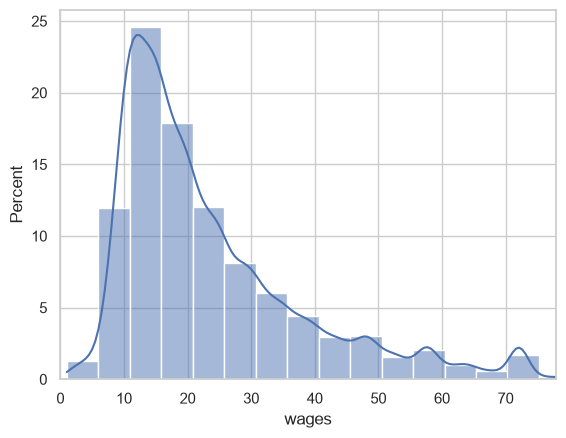

In [12]:
# TODO: Create and label the histogram.
cutoff = earnings["wages"].quantile(0.99)
sns.histplot(data=earnings, x='wages', binwidth=5, kde=True, stat = 'percent')
plt.xlim(0,cutoff)

**Interpretation:** TODO

### 2. How common is each education level?

Create a **count plot** for `education`. Put education on the y-axis so long category names remain readable. Order the bars by frequency.

Code hints:

```python
education_order = earnings["education"].value_counts().index
sns.countplot(data=earnings, y="education", order=education_order, color="...")
```

Which education group is largest? Approximately how many observations are in the smallest group?

Text(0.5, 1.0, 'Viz')

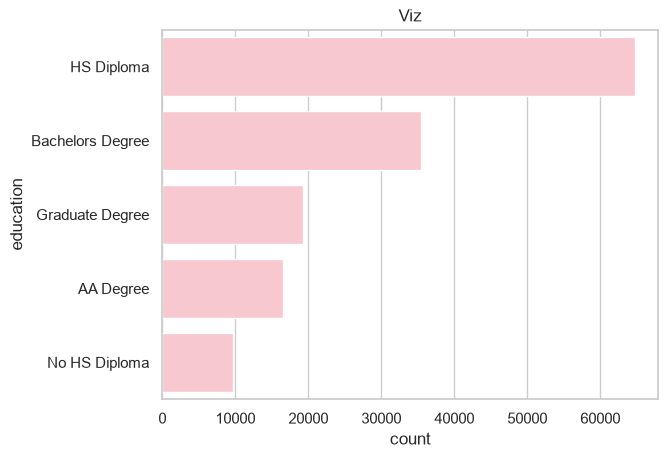

In [15]:
# TODO: Create and label the count plot.
sns.countplot(data=earnings, y="education", color="pink")
plt.title("Viz")


**Interpretation:** TODO

### 3. How do wages vary across education levels?

Create a **box plot** with `wages` on the x-axis and `education` on the y-axis. Use `showfliers=False` to keep extreme values from compressing the boxes. Use a meaningful education order rather than alphabetical order.

Code hints:

```python
education_order = ["No HS Diploma", "HS Diploma", "AA Degree",
                   "Bachelors Degree", "Graduate Degree"]
sns.boxplot(data=earnings, x="wages", y="education",
            order=education_order, showfliers=False)
```

Compare medians and interquartile ranges. Does every person with more education earn more than every person with less education?

<Axes: xlabel='wages', ylabel='education'>

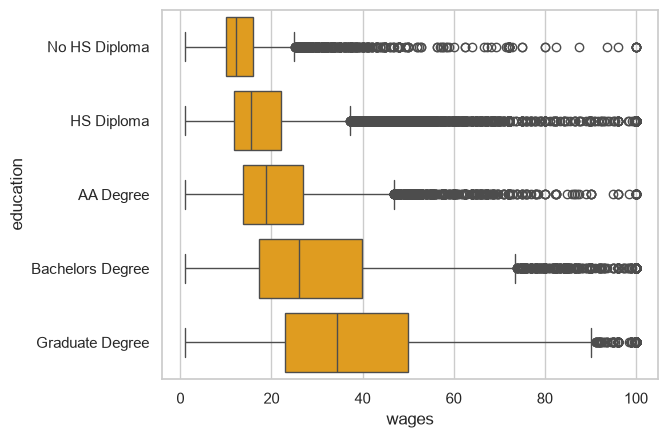

In [18]:
# TODO: Create and label the box plot.
education_order = ["No HS Diploma", "HS Diploma", "AA Degree",
                   "Bachelors Degree", "Graduate Degree"]
sns.boxplot(data=earnings, x="wages", y="education", order = education_order, color = 'orange')

**Interpretation:** TODO

### 4. What is the relationship between age and wages?

Create a **scatter plot** of `age` and `wages`. Because the dataset is large, draw a reproducible random sample first. Use small, transparent points to reveal areas where observations overlap.

Code hints:

```python
plot_sample = earnings.sample(n=5000, random_state=42)
sns.scatterplot(data=plot_sample, x="age", y="wages",
                alpha=0.25, s=20, linewidth=0)
```

Describe the direction, form, and strength of the relationship. Note any visible outliers or changes in variability.

<Axes: xlabel='age', ylabel='wages'>

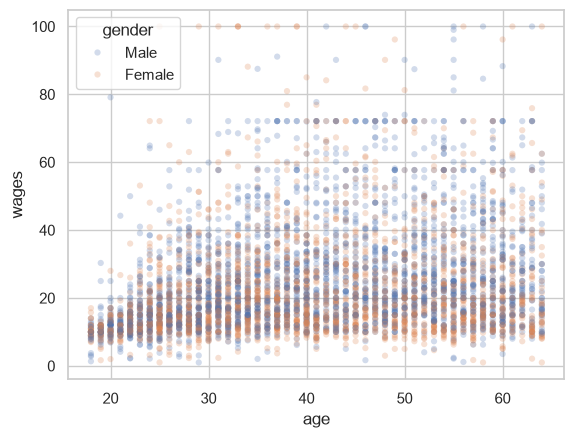

In [54]:
# TODO: Create and label the scatter plot.
plot_sample = earnings.sample(n=5000, random_state=42)
sns.scatterplot(data=plot_sample, x="age", y="wages", alpha=0.25, s=20, linewidth=0, hue='gender')

**Interpretation:** TODO

## Part 2: Lighter guidance

You are still given a recommended plot family, but you must choose the variables, parameters, ordering, and styling.

### 5. Are workers distributed across occupations similarly by gender?

Use a **count plot** with a `hue`. Consider whether raw counts or percentages answer the question more fairly, and sort or orient the categories for readability.

State one important limitation of comparing raw counts between groups.

<Axes: xlabel='percent', ylabel='occup'>

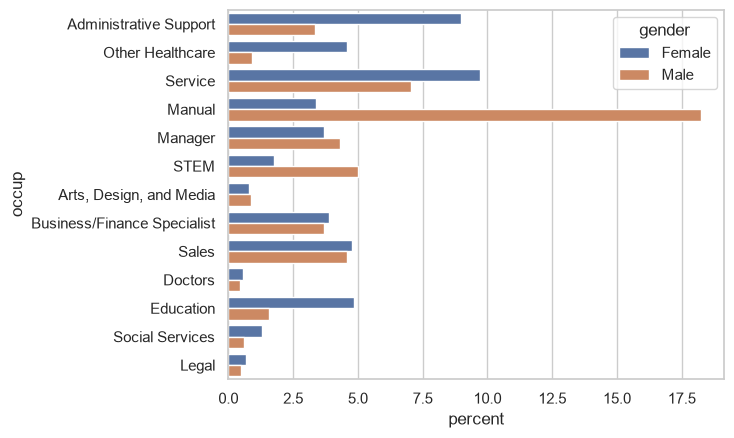

In [61]:
# TODO
sns.countplot(data=earnings, y= 'occup', hue= 'gender', stat='percent')


**Interpretation:** TODO

### 6. How does the wage distribution differ between wage and salary workers?

Use either overlapping **histograms** or a faceted distribution plot. Make the two groups easy to compare, and address the right-skewed wage distribution in a defensible way.

Useful options may include `hue`, `element`, `common_norm`, `col`, `xlim`, or a logarithmic scale.

In [ ]:
# TODO


**Interpretation:** TODO

### 7. Which occupation groups have the highest typical wages?

Create a **bar plot** that compares a summary of `wages` across occupations. Decide whether the mean or median is the more appropriate definition of "typical" for these data. Sort the groups by the statistic you chose.

Hint: `sns.barplot` uses the mean by default. You can pass another function to `estimator`, such as `estimator="median"` in recent Seaborn versions. Decide whether uncertainty bars help answer this question.

In [ ]:
# TODO


**Interpretation:** TODO

### 8. Does the age-wage pattern differ by gender?

Use a **regression plot** or a scatter plot with fitted trend lines. Sampling or summarizing the data is encouraged. Make sure the groups can be distinguished without obscuring the overall pattern.

Possible tools include `sns.lmplot`, `sns.regplot`, `hue`, `lowess`, and `scatter_kws`.

In [ ]:
# TODO


**Interpretation:** TODO

## Part 3: Choose the visualization

For each question below, choose an appropriate Seaborn plot. Before writing code, add one sentence explaining why your plot type fits the variables and the comparison.

### 9. Do wage distributions differ across racial groups?

Your visualization should show more than one summary statistic and should not allow a few extreme observations to hide the main pattern.

In [ ]:
# Plot choice and reason: TODO

# TODO: Create the visualization.


**Interpretation:** TODO

### 10. How does the number of children vary with age?

Choose a plot that clearly communicates the relationship between a discrete numeric variable and age. Consider whether plotting every row or summarizing within groups will be more readable.

In [ ]:
# Plot choice and reason: TODO

# TODO: Create the visualization.


**Interpretation:** TODO

### 11. Is the education-wage pattern similar for workers born inside and outside the country?

Choose a plot that allows comparisons both across education levels and between the two `foreign_born` groups.

In [ ]:
# Plot choice and reason: TODO

# TODO: Create the visualization.


**Interpretation:** TODO

### 12. What is one relationship in these data that deserves further investigation?

Write your own focused question involving at least three variables. Create one polished visualization that addresses it. Use color or faceting only when it adds information.

Your response must include:

- Your research question
- Why you selected this plot type
- The visualization
- A concise interpretation
- One limitation or follow-up question

In [ ]:
# Research question: TODO
# Plot choice and reason: TODO

# TODO: Create the visualization.


**Interpretation and limitation:** TODO

## Optional challenge: Use survey weights

The variable `earningwt` indicates how much each observation contributes to population estimates. Revisit one count or distribution question using weights, then compare it with your unweighted result.

Some Seaborn functions accept `weights="earningwt"`. For weighted summaries that a plotting function does not support directly, calculate the summary with pandas or NumPy first and then visualize the summarized table. Clearly label weighted values as estimates.

In [ ]:
# TODO (optional)


## Final reflection

1. Which visualization revealed the most surprising pattern?
2. Which plot required the most design decisions?
3. Name one conclusion that these data and plots cannot support.
4. What additional variable would you most want in the dataset, and why?